
# Lab 7: Classical Control of DC Motor

## Objective
To model a DC motor mathematically and design and
simulate P, PD, PI, and PID controllers for speed control.

The performance of the controllers will be compared
using rise time, settling time, overshoot, and
steady-state error.

## Software
Python, Jupyter Notebook, NumPy, SciPy,
Matplotlib and Pandas.


In [1]:
%pip install numpy scipy matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd

print("Lab 7 environment is ready!")
print("NumPy version:", np.__version__)
print("SciPy version:", __import__("scipy").__version__)

Lab 7 environment is ready!
NumPy version: 1.26.4
SciPy version: 1.11.4


In [3]:
# Step 2: Define DC Motor Parameters

# Assumed parameters for simulation
Ra = 1.0       # Armature resistance (ohm)
La = 0.5       # Armature inductance (H)
J = 0.01       # Rotor moment of inertia (kg m^2)
B = 0.1        # Viscous friction coefficient (N m s/rad)
Kt = 0.01      # Torque constant (N m/A)
Kb = 0.01      # Back EMF constant (V s/rad)

print("DC Motor Parameters")
print("-------------------")
print("Armature resistance Ra =", Ra, "ohm")
print("Armature inductance La =", La, "H")
print("Moment of inertia J =", J, "kg m^2")
print("Viscous friction B =", B)
print("Torque constant Kt =", Kt)
print("Back EMF constant Kb =", Kb)

DC Motor Parameters
-------------------
Armature resistance Ra = 1.0 ohm
Armature inductance La = 0.5 H
Moment of inertia J = 0.01 kg m^2
Viscous friction B = 0.1
Torque constant Kt = 0.01
Back EMF constant Kb = 0.01


In [4]:
# Step 2.2: Construct the DC Motor Transfer Function

numerator = [Kt]

denominator = [
    La * J,
    La * B + Ra * J,
    Ra * B + Kt * Kb
]

motor = signal.TransferFunction(numerator, denominator)

print("DC Motor Transfer Function")
print("Numerator coefficients:", numerator)
print("Denominator coefficients:", denominator)
print(motor)

DC Motor Transfer Function
Numerator coefficients: [0.01]
Denominator coefficients: [0.005, 0.060000000000000005, 0.10010000000000001]
TransferFunctionContinuous(
array([2.]),
array([ 1.  , 12.  , 20.02]),
dt: None
)


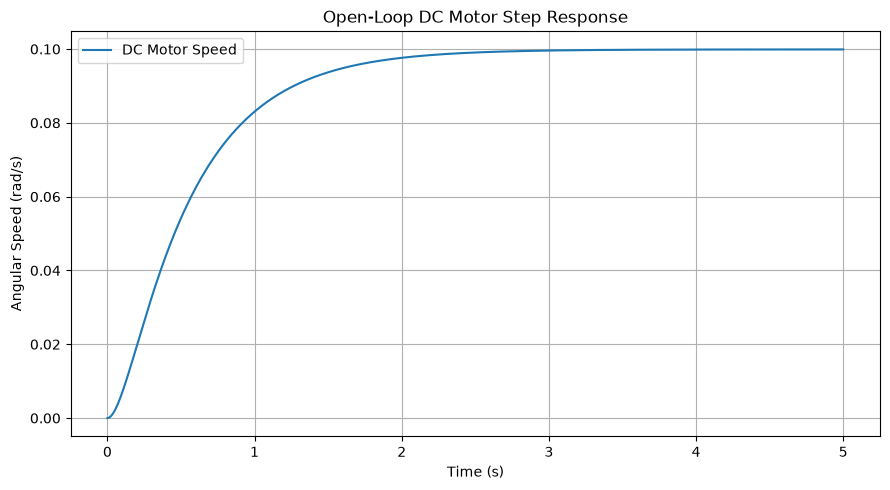

Final simulated speed: 0.09989449892398641 rad/s


In [5]:
# Step 2.3: Open-Loop Speed Response to a 1 V Step

t = np.linspace(0, 5, 1000)

t, speed = signal.step(motor, T=t)

plt.figure(figsize=(9, 5))
plt.plot(t, speed, label="DC Motor Speed")
plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("Open-Loop DC Motor Step Response")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Final simulated speed:", speed[-1], "rad/s")

In [6]:

# Step 3: P Controller Design

# Reference speed and proportional gain
reference_speed = 1.0  # rad/s
Kp = 10.0

# Closed-loop transfer function:
# T(s) = Kp*G(s) / (1 + Kp*G(s))

closed_num = np.polymul([Kp], numerator)
closed_den = np.polyadd(
    denominator,
    np.polymul([Kp], numerator)
)

p_controller = signal.TransferFunction(
    closed_num, closed_den
)

print("P Controller Gain Kp =", Kp)
print("Closed-loop numerator:", closed_num)
print("Closed-loop denominator:", closed_den)
print(p_controller)


P Controller Gain Kp = 10.0
Closed-loop numerator: [0.1]
Closed-loop denominator: [0.005  0.06   0.2001]
TransferFunctionContinuous(
array([20.]),
array([ 1.  , 12.  , 40.02]),
dt: None
)


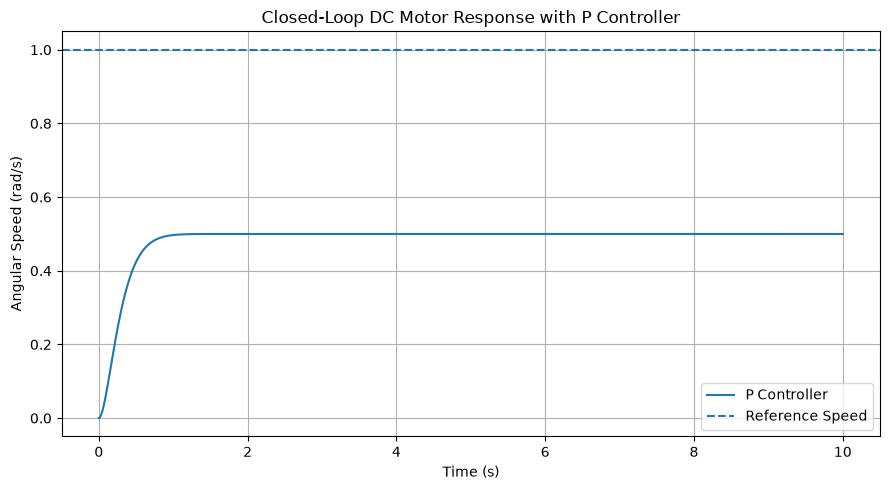

Reference speed: 1.0 rad/s
Final speed: 0.49975012493753196 rad/s
Steady-state error: 0.500249875062468 rad/s


In [7]:

# Step 3.3: P Controller Step Response

t = np.linspace(0, 10, 2000)

t, y_p = signal.step(
    p_controller, T=t
)

# Scale the unit-step response to the reference speed
y_p = reference_speed * y_p

plt.figure(figsize=(9, 5))
plt.plot(t, y_p, label="P Controller")
plt.axhline(
    reference_speed,
    linestyle="--",
    label="Reference Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("Closed-Loop DC Motor Response with P Controller")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Reference speed:", reference_speed, "rad/s")
print("Final speed:", y_p[-1], "rad/s")
print(
    "Steady-state error:",
    reference_speed - y_p[-1],
    "rad/s"
)


In [8]:

# Step 4: PD Controller Design

Kp_pd = 10.0
Kd = 1.0

# PD controller: C(s) = Kd*s + Kp
pd_num = [Kd, Kp_pd]

# Closed-loop transfer function
pd_open_num = np.polymul(pd_num, numerator)

pd_closed_den = np.polyadd(
    denominator,
    pd_open_num
)

pd_controller = signal.TransferFunction(
    pd_open_num,
    pd_closed_den
)

print("PD Controller Gains")
print("Kp =", Kp_pd)
print("Kd =", Kd)
print("Closed-loop numerator:", pd_open_num)
print("Closed-loop denominator:", pd_closed_den)
print(pd_controller)


PD Controller Gains
Kp = 10.0
Kd = 1.0
Closed-loop numerator: [0.01 0.1 ]
Closed-loop denominator: [0.005  0.07   0.2001]
TransferFunctionContinuous(
array([ 2., 20.]),
array([ 1.  , 14.  , 40.02]),
dt: None
)


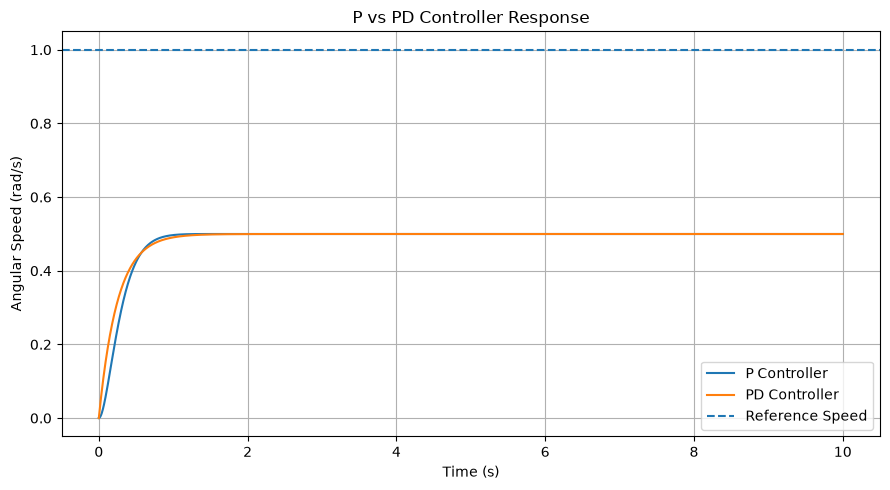

P final speed: 0.49975012493753196 rad/s
PD final speed: 0.49975012493753035 rad/s


In [9]:

# Step 4.3: PD Controller Step Response

t = np.linspace(0, 10, 2000)

t, y_pd = signal.step(pd_controller, T=t)
y_pd = reference_speed * y_pd

plt.figure(figsize=(9, 5))
plt.plot(t, y_p, label="P Controller")
plt.plot(t, y_pd, label="PD Controller")
plt.axhline(
    reference_speed,
    linestyle="--",
    label="Reference Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("P vs PD Controller Response")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("P final speed:", y_p[-1], "rad/s")
print("PD final speed:", y_pd[-1], "rad/s")


In [10]:

# Step 5: PI Controller Design

Kp_pi = 10.0
Ki = 5.0

# PI controller: C(s) = (Kp*s + Ki) / s
pi_num = [Kp_pi, Ki]
pi_den = [1, 0]

# Multiply controller and motor transfer functions
pi_open_num = np.polymul(pi_num, numerator)
pi_open_den = np.polymul(pi_den, denominator)

# Unity negative feedback:
# T(s) = C(s)G(s) / (1 + C(s)G(s))

pi_closed_den = np.polyadd(
    pi_open_den,
    pi_open_num
)

pi_controller = signal.TransferFunction(
    pi_open_num,
    pi_closed_den
)

print("PI Controller Gains")
print("Kp =", Kp_pi)
print("Ki =", Ki)
print("Closed-loop numerator:", pi_open_num)
print("Closed-loop denominator:", pi_closed_den)
print(pi_controller)


PI Controller Gains
Kp = 10.0
Ki = 5.0
Closed-loop numerator: [0.1  0.05]
Closed-loop denominator: [0.005  0.06   0.2001 0.05  ]
TransferFunctionContinuous(
array([20., 10.]),
array([ 1.  , 12.  , 40.02, 10.  ]),
dt: None
)


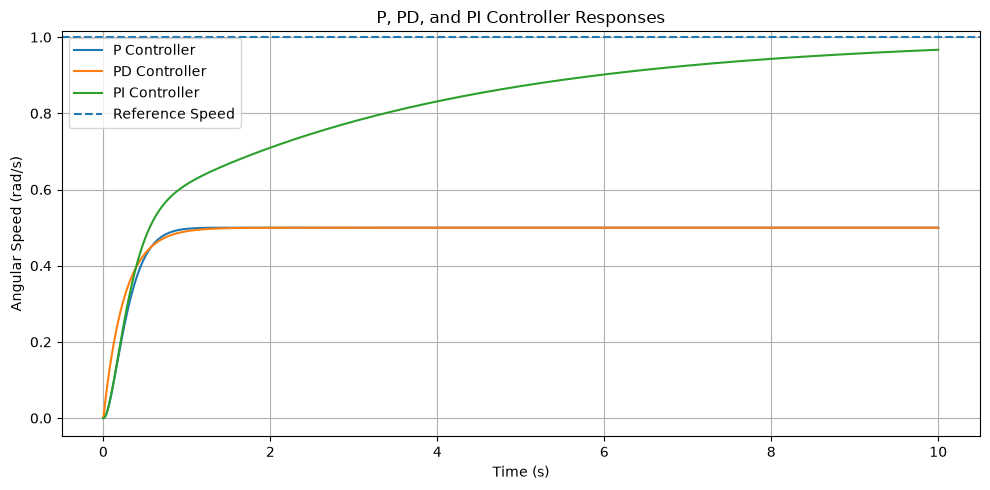

P final speed: 0.49975012493753196 rad/s
PD final speed: 0.49975012493753035 rad/s
PI final speed: 0.9669414485392746 rad/s


In [11]:

# Step 5.3: Compare P, PD, and PI Controllers

t = np.linspace(0, 10, 2000)

t, y_pi = signal.step(pi_controller, T=t)
y_pi = reference_speed * y_pi

plt.figure(figsize=(10, 5))
plt.plot(t, y_p, label="P Controller")
plt.plot(t, y_pd, label="PD Controller")
plt.plot(t, y_pi, label="PI Controller")
plt.axhline(
    reference_speed,
    linestyle="--",
    label="Reference Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("P, PD, and PI Controller Responses")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("P final speed:", y_p[-1], "rad/s")
print("PD final speed:", y_pd[-1], "rad/s")
print("PI final speed:", y_pi[-1], "rad/s")


In [12]:

# Step 6: PID Controller Design

Kp_pid = 10.0
Ki_pid = 5.0
Kd_pid = 1.0

# PID controller:
# C(s) = (Kd*s^2 + Kp*s + Ki) / s

pid_num = [Kd_pid, Kp_pid, Ki_pid]
pid_den = [1, 0]

# Open-loop transfer function
pid_open_num = np.polymul(pid_num, numerator)
pid_open_den = np.polymul(pid_den, denominator)

# Unity negative feedback
pid_closed_den = np.polyadd(
    pid_open_den,
    pid_open_num
)

pid_controller = signal.TransferFunction(
    pid_open_num,
    pid_closed_den
)

print("PID Controller Gains")
print("Kp =", Kp_pid)
print("Ki =", Ki_pid)
print("Kd =", Kd_pid)
print("Closed-loop numerator:", pid_open_num)
print("Closed-loop denominator:", pid_closed_den)
print(pid_controller)


PID Controller Gains
Kp = 10.0
Ki = 5.0
Kd = 1.0
Closed-loop numerator: [0.01 0.1  0.05]
Closed-loop denominator: [0.005  0.07   0.2001 0.05  ]
TransferFunctionContinuous(
array([ 2., 20., 10.]),
array([ 1.  , 14.  , 40.02, 10.  ]),
dt: None
)


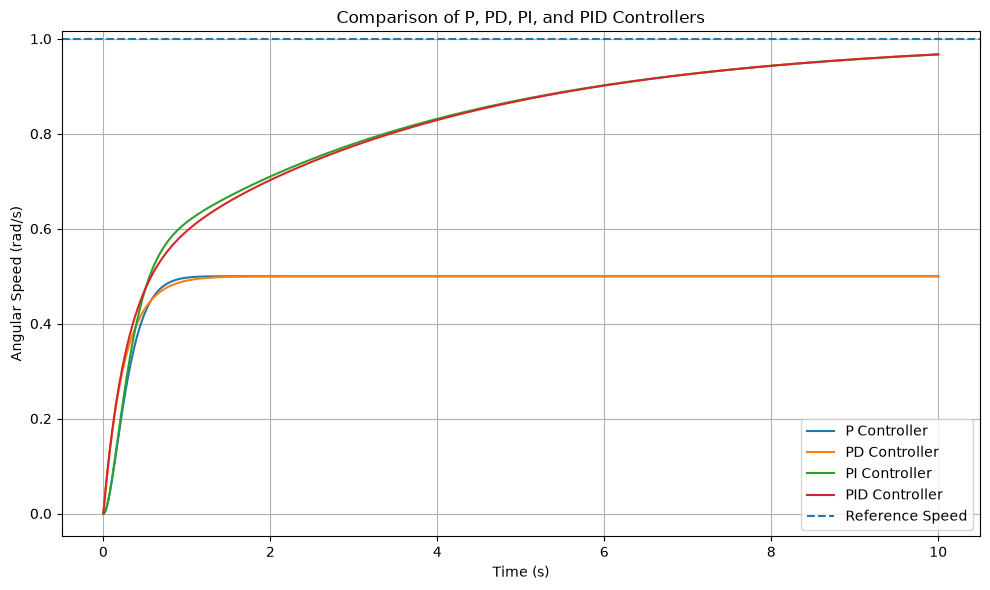

Final speeds after 10 seconds:
P: 0.49975012493753196 rad/s
PD: 0.49975012493753035 rad/s
PI: 0.9669414485392746 rad/s
PID: 0.9673336741808902 rad/s


In [13]:

# Step 6.2: Compare All Four Controllers

t = np.linspace(0, 10, 2000)

t, y_pid = signal.step(pid_controller, T=t)
y_pid = reference_speed * y_pid

plt.figure(figsize=(10, 6))

plt.plot(t, y_p, label="P Controller")
plt.plot(t, y_pd, label="PD Controller")
plt.plot(t, y_pi, label="PI Controller")
plt.plot(t, y_pid, label="PID Controller")

plt.axhline(
    reference_speed,
    linestyle="--",
    label="Reference Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("Comparison of P, PD, PI, and PID Controllers")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Final speeds after 10 seconds:")
print("P:", y_p[-1], "rad/s")
print("PD:", y_pd[-1], "rad/s")
print("PI:", y_pi[-1], "rad/s")
print("PID:", y_pid[-1], "rad/s")


In [15]:

# Step 7: Corrected Controller Performance Metrics

def calculate_metrics(system, reference=1.0, duration=50):
    t = np.linspace(0, duration, 20000)
    t, y = signal.step(system, T=t)
    y = reference * y

    # DC gain = numerator constant / denominator constant
    # Coefficients are ordered from highest power to constant.
    final_value = reference * system.num[-1] / system.den[-1]

    # Rise time: 10% to 90% of final value
    lower = 0.1 * final_value
    upper = 0.9 * final_value

    lower_idx = np.where(y >= lower)[0]
    upper_idx = np.where(y >= upper)[0]

    rise_time = np.nan
    if len(lower_idx) and len(upper_idx):
        rise_time = t[upper_idx[0]] - t[lower_idx[0]]

    # Settling time: remain within 2% of final value
    tolerance = 0.02 * abs(final_value)
    outside = np.where(
        np.abs(y - final_value) > tolerance
    )[0]

    if len(outside) == 0:
        settling_time = 0.0
    elif outside[-1] < len(t) - 1:
        settling_time = t[outside[-1] + 1]
    else:
        # Response has not settled within the simulation duration
        settling_time = np.nan

    # Percentage overshoot relative to final value
    overshoot = max(
        0.0,
        (np.max(y) - final_value) / abs(final_value) * 100
    ) if abs(final_value) > 1e-12 else np.nan

    # Error relative to the desired reference
    steady_state_error = reference - final_value

    return {
        "Final Speed (rad/s)": final_value,
        "Rise Time (s)": rise_time,
        "Settling Time (s)": settling_time,
        "Overshoot (%)": overshoot,
        "Steady-State Error (rad/s)": steady_state_error
    }


systems = {
    "P": p_controller,
    "PD": pd_controller,
    "PI": pi_controller,
    "PID": pid_controller
}

results = {
    name: calculate_metrics(system, reference_speed)
    for name, system in systems.items()
}

performance_table = pd.DataFrame(results).T

print("Corrected Controller Performance Comparison")
display(performance_table.round(5))


Corrected Controller Performance Comparison


,Final Speed (rad/s),Rise Time (s),Settling Time (s),Overshoot (%),Steady-State Error (rad/s)
P,0.49975,0.49002,0.83004,0.00826,0.50025
PD,0.49975,0.55003,0.97755,0.00000,0.50025
PI,1.00000,5.79529,11.85309,0.00000,0.00000
PID,1.00000,5.89029,11.77809,0.00000,0.00000


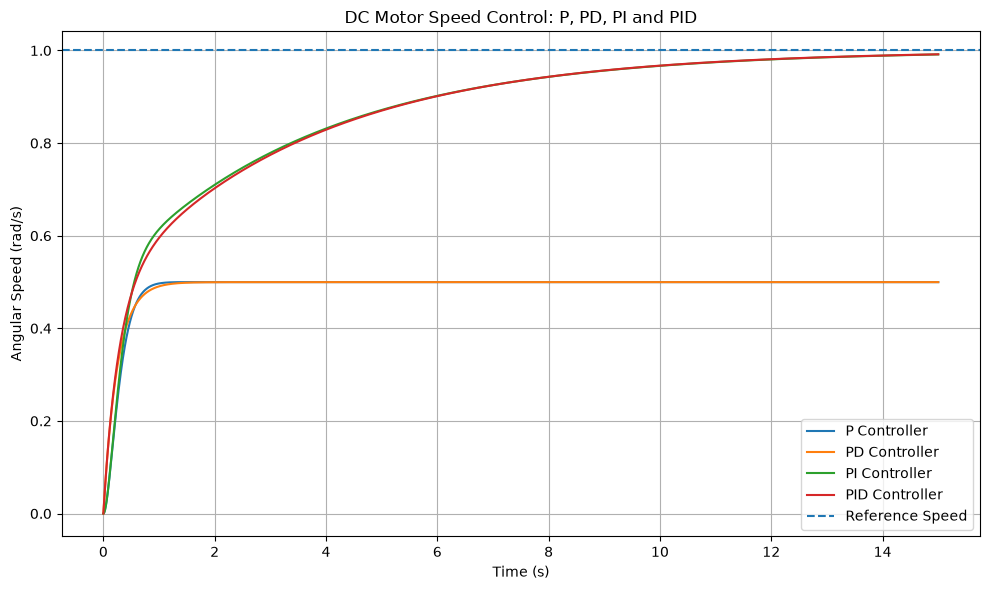

Final comparison graph generated and saved.


In [16]:

# Step 8: Final Comparison Plot

t = np.linspace(0, 15, 3000)

plt.figure(figsize=(10, 6))

for name, system in systems.items():
    t, y = signal.step(system, T=t)
    y = reference_speed * y
    plt.plot(t, y, label=f"{name} Controller")

plt.axhline(
    reference_speed,
    linestyle="--",
    label="Reference Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular Speed (rad/s)")
plt.title("DC Motor Speed Control: P, PD, PI and PID")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("dc_motor_controller_comparison.png", dpi=300)
plt.show()

print("Final comparison graph generated and saved.")


## Conclusion

In this experiment, a DC motor was mathematically modelled using its electrical and mechanical equations. The motor transfer function was derived and implemented in Python using NumPy, SciPy, and Matplotlib.

P, PD, PI, and PID controllers were designed and their speed responses were simulated for a reference speed of 1 rad/s.

The P and PD controllers exhibited steady-state errors of approximately 0.50025 rad/s. The PI and PID controllers achieved approximately zero steady-state error. The responses were compared using rise time, settling time, overshoot, and steady-state error.

The results demonstrate that integral control improves steady-state tracking accuracy. The performance of each controller depends on the selected controller gains and the motor parameters.

**Assumption:** The motor parameters and controller gains were selected for simulation because numerical parameter values were not provided in the assignment. Zero load torque was assumed, and the feedback system used unity negative feedback.